# Tópicos por período legal

Este notebook responde: **sobre o que falam os anúncios, e isso muda ao longo do século XIX?**
Usamos o modelo de tópicos `t5` (corpus `corp3`, campos `c5`), já gravado no banco compartilhado do grupo.
O modelo antigo `t4` (6 tópicos) aparece só na seção 8, para comparação.


Cada gráfico vem com uma ou duas frases dizendo o que ele mostra. Os números dessas frases foram lidos da saída
da própria execução; se o banco mudar, **confira os números de novo**.

> **Cuidado ao ler:** os anúncios foram achados por **frases de busca**, não por sorteio. O que aparece aqui descreve
> o que a busca encontrou, não todos os anúncios do século XIX. Os **nomes** dos tópicos são **hipóteses do grupo**, não fatos.

## 1. O que é um tópico e por que k = 6
**Um tópico é um grupo de palavras que costumam aparecer juntas nos mesmos anúncios.** O programa (LDA) não lê o sentido:
ele só agrupa palavras. Quem dá nome ao grupo somos nós, olhando as palavras e os anúncios.

**Por que 6 tópicos (k = 6)?** Rodamos o modelo várias vezes com sementes diferentes (ver `scripts/estabilidade_topicos.py`)
e medimos quantos tópicos **se repetem** (similaridade de cosseno ≥ 0,8). Com k = 4, 56% dos tópicos se repetem; com k = 6, 59%;
com k = 8, 50%; com k = 10, 29%; com k = 12, 44%. Não cai de forma regular, mas k = 10 é o pior. Mantemos k = 6 (e não k = 4) para separar mais temas. Mesmo em k = 8, quatro temas se repetem muito bem nas
sementes: fuga (0,93), serviço doméstico (0,90), ama de leite (0,85) e aluguel de homens (0,81).
**O resultado também depende da semente do sorteio:** com uma semente fixa, 3 anúncios a mais já reorganizaram todos os tópicos. Por isso usamos a semente mais representativa entre 10.
Ou seja, a estabilidade é **moderada**: os resultados abaixo são pistas, não medidas exatas.

## Preparação: ler o banco
O banco devolve no máximo 1000 linhas por consulta, então lemos em blocos (paginação).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hdb import config
from hdb.banco import BancoSupabase

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)
db = BancoSupabase().cliente      # lê o config/.env pelo módulo hdb

def ler_tudo(consulta, bloco=1000):
    """Executa a consulta em blocos de 1000 linhas e junta o resultado."""
    linhas, inicio = [], 0
    while True:
        parte = consulta().range(inicio, inicio + bloco - 1).execute().data
        linhas += parte
        if len(parte) < bloco:
            return pd.DataFrame(linhas)
        inicio += bloco

MODELO = config.VERSAO_TOPICOS
COMPARA = "t4"
palavras = ler_tudo(lambda: db.table("topico_palavras").select("versao,topico,palavra,peso")
                    .in_("versao", [MODELO, COMPARA]).order("versao").order("topico").order("peso", desc=True))
dist = ler_tudo(lambda: db.table("anuncio_topicos").select("anuncio_id,topico,proporcao")
                .eq("versao", MODELO).order("anuncio_id").order("topico"))
anuncios = ler_tudo(lambda: db.table("anuncios_completos")
                    .select("id,periodo_legal,c_tipo,c_sexo,c_idade_min,c_idade_max,ano,texto")
                    .eq("versao", config.VERSAO_ANUNCIOS).eq("c_versao", config.VERSAO_CAMPOS).order("id"))
print(f"{dist['anuncio_id'].nunique()} anúncios no modelo {MODELO}; {len(anuncios)} anúncios com campos {config.VERSAO_CAMPOS} no banco")

2012 anúncios no modelo t5; 31769 anúncios com campos c5 no banco


In [2]:
PERIODOS = ["antes de 1831", "1831–1850", "1850–1871", "1871–1888"]
def periodo_curto(p):
    return p if p.startswith("antes") else p.split(" ")[0]

# Nomes SUGERIDOS (provisórios): o grupo deve confirmar
# Nomes SUGERIDOS: o LDA numera os tópicos ao acaso (a cada rodada o T0 pode ser outro), então cada nome vem das
# palavras de referência abaixo: o tópico recebe o nome cujas palavras mais aparecem entre as suas 12 de maior peso.
REFERENCIAS = {
    "Fuga: nome, idade e dono": {"anos", "dia", "escravo", "idade", "tiver", "nome", "contra", "souber", "dias", "cor"},
    "Fuga: roupa levada e nação": {"levou", "nacao", "fugiu", "levar", "sera", "corrente", "dia", "preto"},
    "Ama de leite": {"leite", "ama", "meses", "carinhosa", "parto", "criancas", "parda"},
    "Serviço doméstico (aluguel e venda de mulheres)": {"lava", "cozinha", "engoma", "lavar", "engomar", "cozinhar", "servico", "aluga", "preta"},
    "Venda de moleques e pretos (lotes)": {"moleque", "pretos", "dois", "vendem", "pagem", "proprio", "cozinheiro"},
    "Venda com preço e qualidades": {"preco", "perfeito", "bonita", "pardo", "forno", "bem", "todo", "servico", "vende"},
}
from scipy.optimize import linear_sum_assignment
_topo = {t: set(g.sort_values("peso", ascending=False)["palavra"].head(12)) for t, g in palavras[palavras.versao == MODELO].groupby("topico")}
_ts, _nomes = sorted(_topo), list(REFERENCIAS)
_custo = [[-len(_topo[t] & REFERENCIAS[n]) for n in _nomes] for t in _ts]
NOMES = {_ts[i]: (_nomes[j] if -_custo[i][j] >= 2 else f"Tópico {_ts[i]} (sem nome)") for i, j in zip(*linear_sum_assignment(_custo))}
K = len(NOMES)
rot = lambda t: f"T{t} {NOMES[t]}"

# Uma linha por anúncio do modelo, com o tópico dominante
pivo = dist.pivot(index="anuncio_id", columns="topico", values="proporcao")
base = anuncios.drop_duplicates("id").set_index("id").join(pivo, how="inner")
base["dominante"] = base[list(range(K))].idxmax(axis=1)
base["periodo"] = pd.Categorical(base["periodo_legal"].map(periodo_curto), categories=PERIODOS, ordered=True)
print(len(base), "anúncios na base de análise")
if len(base) != 2012:
    print(f"ATENÇÃO: os comentários deste caderno foram escritos para 2012 anúncios e agora são {len(base)}: "
          "confira os números dos textos antes de usar.")

# Paleta Okabe-Ito, uma cor por tópico
CORES = ["#0072B2", "#D55E00", "#E69F00", "#009E73", "#CC79A7", "#999999"]
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

2012 anúncios na base de análise


## 2. Os tópicos do modelo `t5`
Abaixo, as **12 palavras de maior peso** de cada tópico (as palavras estão sem acento, como no corpus padronizado).
A coluna **Nome sugerido** é uma **proposta provisória**: o grupo precisa confirmar ou trocar.

In [3]:
tab = (palavras[palavras["versao"] == MODELO].groupby("topico")["palavra"].apply(lambda s: ", ".join(s.head(12))))
tabela = pd.DataFrame({"Nome sugerido": [NOMES[t] for t in tab.index], "12 palavras de maior peso": tab.values},
                      index=pd.Index(tab.index, name="Tópico"))
tabela

,Nome sugerido,12 palavras de maior peso
Tópico,,
0,"Fuga: nome, idade e dono","anos, dia, escravo, idade, tiver, nome, contra, corrente, cor, dias, souber, ano"
1,Venda de moleques e pretos (lotes),"vende, anos, preto, dois, bom, moleque, pretos, boa, cozinheiro, proprio, vendem, pagem"
2,Ama de leite,"aluga, leite, ama, preta, servico, precisa, todo, preto, bom, boa, alugar, parda"
3,Venda com preço e qualidades,"vende, anos, bom, preto, bem, servico, todo, perfeito, bonita, pardo, preco, forno"
4,Serviço doméstico (aluguel e venda de mulheres),"aluga, preta, lava, vende, cozinha, preto, engoma, lavar, servico, boa, cozinheiro, cozinhar"
5,Fuga: roupa levada e nação,"nome, fugiu, dia, corrente, nacao, levar, escravo, sera, preto, idade, levou, anos"


**Nomes sugeridos (provisórios), dados pelas palavras de cada tópico; o número do tópico muda a cada rodada, o nome acompanha o conteúdo.** Dois tópicos são **fuga** e juntos têm 377 dos 408 anúncios de fuga (92%): **nome, idade e dono** (`nome`, `idade`, `escravo`, `tiver`, `souber`, `contra`: 70 fugas) e **roupa levada e nação** (`fugiu`, `levou`, `nacao`, `levar`, `corrente`: 307 fugas). **Ama de leite** (`leite`, `ama`, `meses`, `carinhosa`) tem 179 das 223 amas de leite. **Serviço doméstico (aluguel e venda de mulheres)** (`lava`, `cozinha`, `engoma`, `lavar`, `cozinhar`) é o maior: 430 dos 809 aluguéis e 172 vendas. Os dois de venda são **venda de moleques e pretos (lotes)** (`moleque`, `pretos`, `dois`, `vendem`, `pagem`) e **venda com preço e qualidades** (`preco`, `perfeito`, `bonita`, `pardo`, `forno`). Estes dois se parecem e podem ser vistos como um só tema de venda de homens e de lotes.

## 3. Os 3 anúncios mais típicos de cada tópico
São os 3 com **maior proporção** daquele tópico. Mostramos os primeiros 250 caracteres do texto original.
Serve para conferir se o nome sugerido faz sentido.

In [4]:
for t in range(K):
    print(f"=== Tópico {t}: {NOMES[t]} ===")
    top3 = base.sort_values(t, ascending=False).head(3)
    for i, r in top3.iterrows():
        txt = " ".join(str(r["texto"]).split())[:250]
        print(f"  [id {i}, {r['periodo']}, tipo {r['c_tipo']}, proporção {r[t]:.2f}] {txt}")
    print()

=== Tópico 0: Fuga: nome, idade e dono ===
  [id 13812, antes de 1831, tipo fuga, proporção 0.99] 47 Ha 3 annos pouco mais ou menos, fa. gira a Antonio José da Mota hum seu escravo da Fazenda da Itaitindiva, por nome Sebastião, erioulo, idade 28 annos, pouco mais ou me. nos, estatura ordinaria, cheio do corpo, ea, e nariz redondo, beiços, e pés g
  [id 6263, 1831–1850, tipo fuga, proporção 0.99] — PAGAR-SE-HA O trabalho de quem pegar, o levar à rua do Conde n. 55, hum escravo de no-: me Vicente, de 24 annos de idade pardo escuro , com cabello de preto, secco, de mediana estatura ,e com pouca barba , que desappareceu hontem 16 do corrente , i
  [id 29167, 1831–1850, tipo fuga, proporção 0.99] FUGIO um Africano , livre, de nome Emygdio, idade de 15 annos , nação Benguella , olhos grandes , côr fula , boa dentadura ; quem o levar á rua Nova das Larangeiras n.5 A, ou á rua Direita n. 48, receberá alviçaras, * — DECLARO que, achando-me gravem

=== Tópico 1: Venda de moleques e pretos (lotes

**Leitura dos exemplos.** Os mais típicos de **fuga** (ids 13812, 6263, 34155, 37223, 29276) são fugas de verdade, com idade, estatura, roupa e dono. Os de **serviço doméstico** (ids 36045, 12052) e de **venda** (ids 28828, 23839, 28807, 36588, 36543) também combinam com o nome. **Discordâncias:** (a) fuga (nome, idade e dono): o id 29167 é a fuga de "um Africano, livre", que não é escravizado; (b) ama de leite: o id 34171 é um **anúncio de comércio** ("muito finas… 70 por 70") marcado como ama de leite; (c) serviço doméstico: o id 29110 é um aluguel de **preto boleeiro** (homem), que o tópico agrupa por "aluga", "preto", "servico". Ou seja, ainda há **algum ruído**, pequeno, mas ele existe sobretudo em ama de leite, e o tópico de serviço doméstico mistura homens e mulheres.

## 4. Peso de cada tópico por período legal
Para cada período, a **proporção média** de cada tópico nos anúncios daquele período (cada coluna soma 100%).

               T0 Fuga: nome, idade e dono  T1 Venda de moleques e pretos (lotes)  T2 Ama de leite  T3 Venda com preço e qualidades  T4 Serviço doméstico (aluguel e venda de mulheres)  T5 Fuga: roupa levada e nação     n
periodo                                                                                                                                                                                                                     
antes de 1831                         16.5                                    8.6             17.3                              8.8                                                17.2                           31.7    95
1831–1850                             10.8                                   17.6             21.3                             13.1                                                21.9                           15.4   451
1850–1871                              7.2                                   13.1             23.3                  

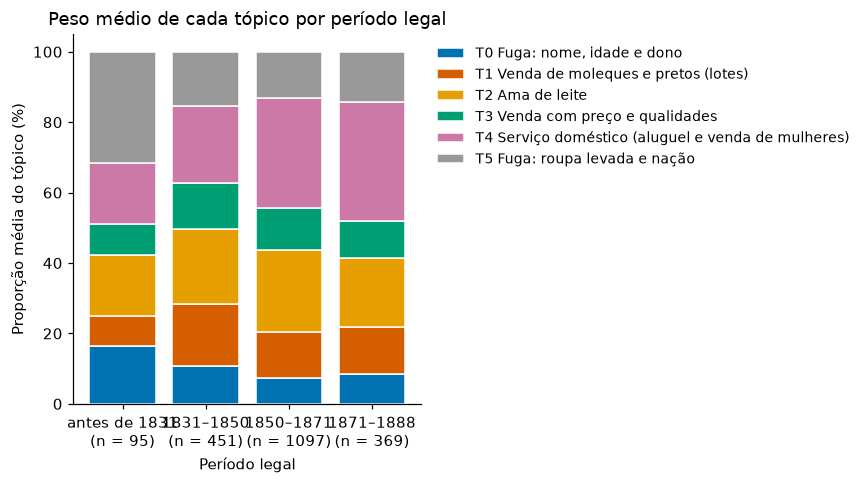

In [5]:
media = base.groupby("periodo", observed=True)[list(range(K))].mean().reindex(PERIODOS)
n_per = base.groupby("periodo", observed=True).size().reindex(PERIODOS)
med = (media * 100).round(1)
med.columns = [rot(t) for t in med.columns]
print(med.assign(n=n_per).to_string())
print("\nComposição por tipo em cada período (% dos anúncios):")
print((pd.crosstab(base["periodo"], base["c_tipo"], normalize="index") * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
fundo = np.zeros(len(PERIODOS))
for t in range(K):
    ax.bar(range(len(PERIODOS)), media[t].values * 100, bottom=fundo, color=CORES[t], edgecolor="white", label=rot(t))
    fundo += media[t].values * 100
ax.set_xticks(range(len(PERIODOS)))
ax.set_xticklabels([f"{p}\n(n = {n_per[p]})" for p in PERIODOS])
ax.set_title("Peso médio de cada tópico por período legal")
ax.set_xlabel("Período legal"); ax.set_ylabel("Proporção média do tópico (%)")
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
fig.tight_layout(); plt.show()

**O que se vê:** os dois tópicos de **fuga somados** caem de 48,2% antes de 1831 para 26,2% em 1831–1850, 20,5% em 1850–1871 e 22,8% em 1871–1888. O de **serviço doméstico** **cresce a cada período**: 17,2%, 21,9%, 31,0% e 33,6%. **Ama de leite** sobe de 17,3% para 23,3% em 1850–1871 e recua para 19,6% em 1871–1888. Os dois tópicos de venda ficam estáveis (entre 8% e 18%). **Cuidado:** a composição por tipo muda muito: fuga é 53,7% do corpus antes de 1831 e 22,0% em 1871–1888 (era 16,6% em 1850–1871), enquanto aluguel vai de 7,4% a 29,0%, 45,2% e 47,4%. Como o tópico acompanha o tipo (seção 7), parte do que parece mudança nos temas vem de **quantos anúncios de cada tipo a busca achou** em cada período. A fuga em 1871–1888 é maior que em 1850–1871 por causa das páginas de cobertura dos anos 1880, e não por mais fugas na época.

## 5. Por sexo
Aqui o tópico entra como **proporção média** entre os anúncios de cada sexo (`f` ou `m`).

> **Ressalva:** o sexo vem de **palavras do anúncio** ("preta", "preto", "moleque"…), e o tipo "ama de leite" é feminino
> **por construção**. Por isso, depois do gráfico, cruzamos **tipo × sexo** e **tipo × tópico** para separar o que
> é efeito do tipo.

{'Feminino': 984, 'Masculino': 794}
c_sexo                                              Feminino  Masculino
T0 Fuga: nome, idade e dono                              5.8       11.0
T1 Venda de moleques e pretos (lotes)                    5.9       23.4
T2 Ama de leite                                         31.4       12.5
T3 Venda com preço e qualidades                          9.8       14.2
T4 Serviço doméstico (aluguel e venda de mulheres)      40.4       17.1
T5 Fuga: roupa levada e nação                            6.7       21.9


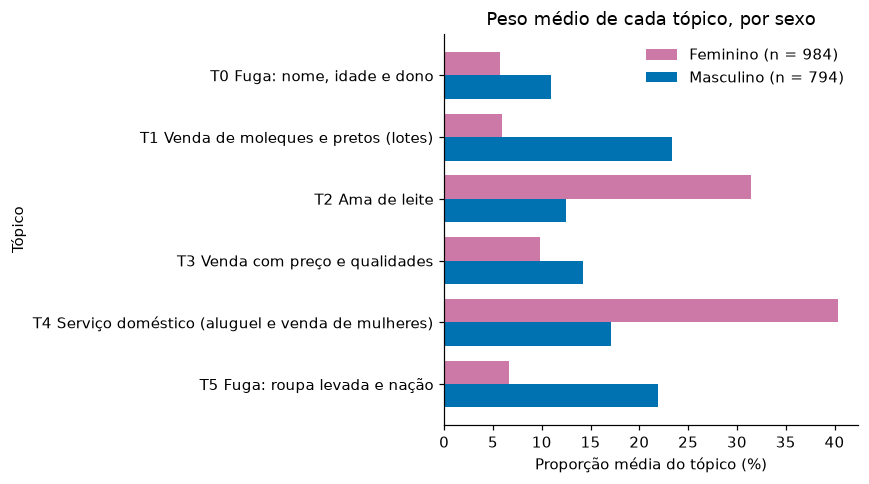

In [6]:
sx = base[base["c_sexo"].isin(["f", "m"])]
n_sx = sx.groupby("c_sexo").size()
m_sx = sx.groupby("c_sexo")[list(range(K))].mean().T * 100
m_sx.index = [rot(t) for t in m_sx.index]
m_sx = m_sx.rename(columns={"f": "Feminino", "m": "Masculino"})
print((n_sx.rename({"f": "Feminino", "m": "Masculino"})).to_dict())
print(m_sx.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(K); h = 0.38
ax.barh(y - h/2, m_sx["Feminino"].values, h, color="#CC79A7", label=f"Feminino (n = {n_sx.get('f', 0)})")
ax.barh(y + h/2, m_sx["Masculino"].values, h, color="#0072B2", label=f"Masculino (n = {n_sx.get('m', 0)})")
ax.set_yticks(y); ax.set_yticklabels(m_sx.index); ax.invert_yaxis()
ax.set_title("Peso médio de cada tópico, por sexo"); ax.set_xlabel("Proporção média do tópico (%)"); ax.set_ylabel("Tópico")
ax.legend(frameon=False)
fig.tight_layout(); plt.show()

In [7]:
# O sexo é efeito do tipo? Tipo x sexo (contagem) e tipo x tópico médio (%)
print(pd.crosstab(base["c_tipo"], base["c_sexo"].fillna("não diz")).to_string())
print()
por_tipo = base.groupby("c_tipo")[list(range(K))].mean() * 100
por_tipo.columns = [f"T{t}" for t in por_tipo.columns]
print(por_tipo.round(1).assign(n=base.groupby("c_tipo").size()).to_string())
print()
# Dentro de um mesmo tipo, f e m diferem? (fuga e venda são os tipos com os dois sexos)
for tipo in ["fuga", "venda"]:
    s = sx[sx["c_tipo"] == tipo]
    if s["c_sexo"].nunique() == 2:
        d = (s.groupby("c_sexo")[list(range(K))].mean() * 100).round(1)
        d.columns = [f"T{t}" for t in d.columns]
        print(f"Tipo {tipo}: n =", s.groupby("c_sexo").size().to_dict()); print(d.to_string()); print()

c_sexo        ambos    f    m  não diz
c_tipo                                
aluguel          44  485  280        0
ama_de_leite     19  192    9        3
compra            5   11   13        0
fuga             17   62  245       84
venda            61  234  247        1

                T0    T1    T2    T3    T4    T5    n
c_tipo                                               
aluguel        5.3   9.5  26.9   8.8  46.5   3.0  809
ama_de_leite   4.9   7.1  67.1   6.7  10.4   3.9  223
compra         9.9  15.0  28.9  24.5  18.9   2.7   29
fuga          21.8   8.5   4.2   3.0   3.8  58.7  408
venda          5.4  27.5   8.8  24.5  29.3   4.6  543

Tipo fuga: n = {'f': 62, 'm': 245}
          T0   T1   T2   T3   T4    T5
c_sexo                                
f       20.0  5.1  8.1  2.3  7.4  57.2
m       20.9  9.3  2.8  3.1  3.0  61.0

Tipo venda: n = {'f': 234, 'm': 247}
         T0    T1    T2    T3    T4   T5
c_sexo                                  
f       4.9  11.4  12.5  21.0  45.9 

**O que se vê:** entre mulheres (n = 984) pesam mais o serviço doméstico (40,4%) e a ama de leite (31,4%); entre homens (n = 794) pesam mais a fuga por roupa e nação (21,9%), a venda de moleques e pretos (23,4%) e o serviço doméstico (17,1%). **Em parte é efeito do tipo:** quase todo anúncio de ama de leite é feminino (192 `f` contra 9 `m`) e a fuga é majoritariamente masculina (245 `m` contra 62 `f`). Dentro da **fuga** a diferença some: o tema de nome, idade e dono é 20,0% (f) e 20,9% (m); o de roupa e nação, 57,2% e 61,0%. Já dentro da **venda** ela **permanece**: nas mulheres pesa o serviço doméstico (45,9%) e nos homens a venda de moleques e pretos (42,2%, contra 11,4% nas mulheres). Com n de 234 e 247, é um sinal razoável, mas ainda uma **pista**.

## 6. Por faixa de idade
Só entram anúncios que **dizem a idade** (usamos o ponto médio quando há intervalo). O número é pequeno,
então **as diferenças entre faixas são frágeis**: veja o `n` de cada linha antes de tirar conclusões.

In [8]:
base["idade"] = base[["c_idade_min", "c_idade_max"]].astype(float).mean(axis=1)
FAIXAS = ["até 12", "13–20", "21–35", "36+"]
base["faixa"] = pd.cut(base["idade"], bins=[-1, 12, 20, 35, 200], labels=FAIXAS)
com_idade = base[base["idade"].notna()]
print(f"{len(com_idade)} de {len(base)} anúncios têm idade")
ti = com_idade.groupby("faixa", observed=True)[list(range(K))].mean() * 100
ti.columns = [f"T{t}" for t in ti.columns]
ti.insert(0, "n", com_idade.groupby("faixa", observed=True).size())
ti.round(1)

317 de 2012 anúncios têm idade


,n,T0,T1,T2,T3,T4,T5
faixa,,,,,,,
até 12,35,13.4,29.3,11.1,25.2,15.8,5.1
13–20,155,10.5,25.7,11.2,18.1,17.3,17.1
21–35,87,15.3,11.7,7.5,17.8,9.8,37.9
36+,40,12.7,28.4,6.8,7.2,14.0,30.9


**Fragilidade:** só 317 dos 2.012 anúncios dizem a idade, e as faixas têm n = 35, 155, 87 e 40. Os tópicos de **fuga** somados pesam 18,5% até 12 anos, 27,6% de 13 a 20, **53,2% de 21 a 35** e 43,6% de 36 em diante: **quem tem idade registrada na fuga é, em geral, adulto**. **Crianças** aparecem sobretudo em venda: até 12 anos, a venda de moleques e pretos pesa 29,3% e a venda com preço e qualidades, 25,2%. São diferenças frágeis: a idade só aparece quando o OCR a leu e a faixa até 12 anos tem 35 anúncios.

## 7. Tópico × tipo de anúncio
Cada anúncio vai para o seu **tópico dominante** (o de maior proporção). A matriz conta quantos anúncios de cada tipo
caem em cada tópico. Se cada tópico fosse "só" um tipo, haveria um bloco forte por coluna.

               T0   T1   T2   T3   T4   T5  Total
c_tipo                                           
aluguel        23   63  230   59  430    4    809
ama_de_leite    8   12  179    6   15    3    223
compra          2    5   10    8    3    1     29
fuga           70   19    6    3    3  307    408
venda          21  161   38  140  172   11    543
Total         124  260  463  216  623  326   2012


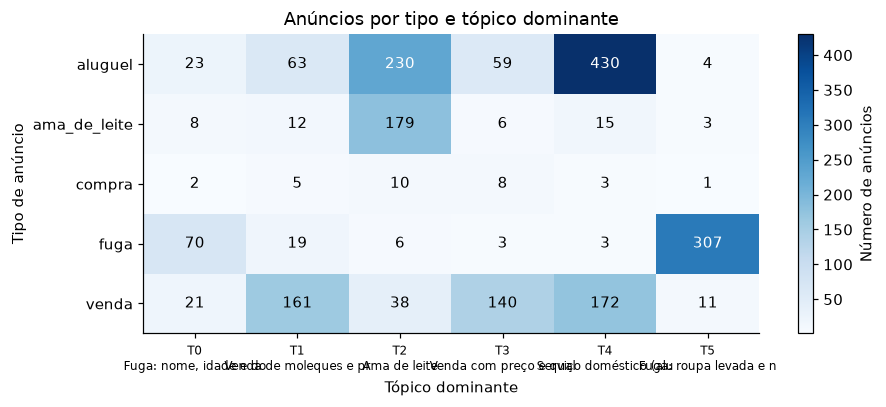

In [9]:
tt = pd.crosstab(base["c_tipo"], base["dominante"])
tt.columns = [f"T{t}" for t in tt.columns]
tt["Total"] = tt.sum(axis=1)
tt.loc["Total"] = tt.sum()
print(tt.to_string())

mat = pd.crosstab(base["c_tipo"], base["dominante"]).reindex(columns=range(K), fill_value=0)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
im = ax.imshow(mat.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(K)); ax.set_xticklabels([f"T{t}\n{NOMES[t][:22]}" for t in range(K)], fontsize=8)
ax.set_yticks(range(len(mat))); ax.set_yticklabels(mat.index)
for i in range(mat.shape[0]):
    for j in range(K):
        v = mat.values[i, j]
        ax.text(j, i, str(v), ha="center", va="center", color="white" if v > mat.values.max() * 0.5 else "black")
ax.set_title("Anúncios por tipo e tópico dominante"); ax.set_xlabel("Tópico dominante"); ax.set_ylabel("Tipo de anúncio")
fig.colorbar(im, ax=ax, label="Número de anúncios")
fig.tight_layout(); plt.show()

**O que se vê:** os tópicos **acompanham bastante o tipo**: 377 dos 408 anúncios de fuga (92%) estão nos dois tópicos de fuga; 179 das 223 amas de leite no de ama de leite (80%); 430 dos 809 aluguéis no de serviço doméstico (53%) e 230 no de ama de leite (28%); e a venda se divide entre serviço doméstico (172), moleques e pretos (161) e preço e qualidades (140). Então, em boa medida, os tópicos **são os tipos** (o modelo não descobriu muito além do que a classificação já dizia). O que os tópicos acrescentam está nas **palavras**: a fuga se divide entre "nome, idade e dono" e "roupa levada e nação", e o serviço doméstico atravessa aluguel e venda de mulheres.

## 8. Comparação com o modelo `t4`
Para cada tópico de `t4`, buscamos o tópico de `t5` mais parecido pela **similaridade de cosseno** entre as distribuições de palavras.

> **Aproximação:** o banco guarda só as **12 palavras de maior peso** de cada tópico. Usamos a união dessas palavras
> como vocabulário e **peso 0** para as ausentes. O resultado é aproximado e ignora a cauda de cada tópico.

In [10]:
pal = palavras.pivot_table(index=["versao", "topico"], columns="palavra", values="peso", fill_value=0)
M2, M3 = pal.loc[COMPARA], pal.loc[MODELO]
vocab = sorted(set(M2.columns) | set(M3.columns))
A = M2.reindex(columns=vocab, fill_value=0).values
B = M3.reindex(columns=vocab, fill_value=0).values
cos = (A / np.linalg.norm(A, axis=1, keepdims=True)) @ (B / np.linalg.norm(B, axis=1, keepdims=True)).T
linhas = []
for i, antigo in enumerate(M2.index):
    j = int(cos[i].argmax())
    linhas.append({"Tópico do modelo antigo": antigo, "Palavras do modelo antigo": ", ".join(palavras[(palavras.versao == COMPARA) & (palavras.topico == antigo)]["palavra"].head(6)) + "…",
                   "Mais parecido no modelo novo": f"T{M3.index[j]} {NOMES[M3.index[j]]}", "Cosseno": round(float(cos[i, j]), 2)})
pd.DataFrame(linhas).set_index("Tópico do modelo antigo")

,Palavras do modelo antigo,Mais parecido no modelo novo,Cosseno
Tópico do modelo antigo,,,
0,"dia, fugiu, nome, corrente, nacao, levar…",T5 Fuga: roupa levada e nação,1.00
1,"preto, vende, bom, anos, aluga, cozinheiro…",T1 Venda de moleques e pretos (lotes),0.85
2,"aluga, preta, leite, ama, servico, precisa…",T2 Ama de leite,0.96
3,"escravo, rio, queira, dias, cidade, fugido…","T0 Fuga: nome, idade e dono",0.38
4,"anos, vende, moleque, idade, senhora, qualquer…",T1 Venda de moleques e pretos (lotes),0.63
5,"preta, lava, aluga, cozinha, engoma, vende…",T4 Serviço doméstico (aluguel e venda de mulheres),0.89


**O que se vê:** os temas do modelo antigo (`t4`, antes da limpeza) que eram claros têm par no novo com cosseno alto: fuga com o de roupa e nação em **1,00**, aluguel de mulheres e ama de leite com ama de leite em **0,96**, serviço doméstico com o de serviço doméstico em **0,89** e venda e aluguel de homens com o de moleques e pretos em **0,85**. **Os dois tópicos fracos e misturados do modelo antigo não têm par:** o de avisos com lugar e data casa só em **0,38** com o de nome, idade e dono, e o de venda de moleques e colunas mistas em **0,63**. Isso indica que **a limpeza removeu o ruído que formava esses dois tópicos**. A perplexidade (830, contra 946 no modelo antigo) não é uma comparação direta, porque o corpus mudou. É uma comparação **aproximada** (só 12 palavras por tópico).

## 9. E se os aluguéis duvidosos entrassem? (variante `t5i`)
O `aluguel_incerto` são anúncios de aluguel em que o texto **não diz** se a pessoa era escravizada ("precisa-se de uma criada").
Eles ficam fora do modelo principal. Aqui ajustamos o mesmo modelo **com** eles (`t5i`) e comparamos a parcela de cada tema por período.
Os temas recebem o nome pelo mesmo critério de palavras, então a comparação é pelo **nome**, não pelo número.

In [11]:
VARIANTE = MODELO + "i"
pal_i = ler_tudo(lambda: db.table("topico_palavras").select("versao,topico,palavra,peso").eq("versao", VARIANTE)
                 .order("topico").order("peso", desc=True))
dist_i = ler_tudo(lambda: db.table("anuncio_topicos").select("anuncio_id,topico,proporcao").eq("versao", VARIANTE)
                  .order("anuncio_id").order("topico"))
topo_i = {t: set(g.sort_values("peso", ascending=False)["palavra"].head(12)) for t, g in pal_i.groupby("topico")}
ts_i = sorted(topo_i)
custo_i = [[-len(topo_i[t] & REFERENCIAS[n]) for n in _nomes] for t in ts_i]
nomes_i = {ts_i[i]: (_nomes[j] if -custo_i[i][j] >= 2 else f"Tópico {ts_i[i]} (sem nome)") for i, j in zip(*linear_sum_assignment(custo_i))}
pivo_i = dist_i.pivot(index="anuncio_id", columns="topico", values="proporcao").rename(columns=nomes_i)
com_i = anuncios.drop_duplicates("id").set_index("id")[["periodo_legal"]].join(pivo_i, how="inner")
com_i["periodo"] = pd.Categorical(com_i["periodo_legal"].map(periodo_curto), categories=PERIODOS, ordered=True)
sem = base[list(range(K))].rename(columns=NOMES).assign(periodo=base["periodo"])
media_sem = (sem.groupby("periodo", observed=True).mean() * 100).round(1).reindex(PERIODOS)
media_com = (com_i.groupby("periodo", observed=True)[list(pivo_i.columns)].mean() * 100).round(1).reindex(PERIODOS)
tab = pd.concat({"sem os duvidosos (t5)": media_sem, "com os duvidosos (t5i)": media_com}, axis=1)
print(f"{len(sem)} anúncios sem e {len(com_i)} com os aluguéis duvidosos (proporção média de cada tema por período, %)")
tab.T

2012 anúncios sem e 2182 com os aluguéis duvidosos (proporção média de cada tema por período, %)


periodo                                                                 antes de 1831  1831–1850  1850–1871  1871–1888
sem os duvidosos (t5)  Fuga: nome, idade e dono                                  16.5       10.8        7.2        8.4
                       Venda de moleques e pretos (lotes)                         8.6       17.6       13.1       13.4
                       Ama de leite                                              17.3       21.3       23.3       19.6
                       Venda com preço e qualidades                               8.8       13.1       12.0       10.6
                       Serviço doméstico (aluguel e venda de mulheres)           17.2       21.9       31.0       33.6
                       Fuga: roupa levada e nação                                31.7       15.4       13.3       14.4
com os duvidosos (t5i) Ama de leite                                               9.5       17.3       18.5       22.3
                       Venda com preço e qualidades                              12.3       18.3       20.5       15.5
                       Fuga: roupa levada e nação                                45.6       20.1       15.0       15.7
                       Tópico 3 (sem nome)                                        7.9       12.2       11.2       11.3
                       Venda de moleques e pretos (lotes)                        16.7       18.8       14.8       13.7
                       Serviço doméstico (aluguel e venda de mulheres)            8.0       13.3       19.9       21.6

**O que se vê:** com os aluguéis duvidosos o corpus passa de 2.012 para 2.182 anúncios (+170). O modelo escolhe **uma divisão diferente da fuga** (um tópico a menos de fuga e um sem nome claro), então a comparação por nome é parcial. Mesmo assim, **a conclusão se mantém**: o serviço doméstico **sobe a cada período** (de 17,2% a 33,6% sem os duvidosos; de 8,0% a 21,6% com eles); a fuga **cai de perto da metade para cerca de um quinto** (a fuga por roupa e nação vai de 45,6% antes de 1831 a 15,7% em 1871–1888 com os duvidosos); e ama de leite e venda variam pouco. **O que muda é o nível**: os aluguéis duvidosos diluem o serviço doméstico (que é onde eles caem). Ou seja, decidir se eles entram **muda os números, mas não a direção** do resultado.

## 10. O que os resultados dizem e o que não dizem

**O que sustenta (com as ressalvas abaixo):**

- Os tópicos de **fuga somados caem** de 48,2% antes de 1831 para 22,8% em 1871–1888 (seção 4). **Mas** a fuga também cai de 53,7% para 22,0% dos anúncios do corpus, então o tópico pode só refletir isso.
- O tópico de **serviço doméstico cresce** de 17,2% antes de 1831 a 33,6% em 1871–1888, passando por 21,9% e 31,0%. Acompanha o aluguel, que vai de 7,4% a 47,4% do corpus. A direção se mantém **com os aluguéis duvidosos** (seção 9).
- Na **venda**, os anúncios de mulheres puxam o serviço doméstico (45,9%) e os de homens a venda de moleques e pretos (42,2%) (seção 5).
- Os temas de **fuga, ama de leite e serviço doméstico** reaparecem entre o modelo antigo e o novo (cosseno de 0,89 a 1,00) e nos exemplos lidos (seções 3 e 8).

**O que NÃO dizem:**

- **Não é amostra da população.** Os anúncios vêm de **frases de busca**; mudanças entre períodos podem refletir **o que a busca achou** (a composição por tipo muda), não o que se anunciava de fato.
- **Desigualdade entre períodos:** 2.012 anúncios (95, 451, 1.097 e 369 por período). O período 1871–1888 não tem nada de **1887 e 1888** e quase nada de 1886, então **ainda não dá para falar da Lei Áurea**.
- **Estabilidade moderada:** só 59% dos tópicos se repetem com k = 6. E o resultado **muda com poucos anúncios a mais ou a menos**: com uma semente fixa, 3 anúncios a mais reorganizaram todos os tópicos. Por isso o modelo usa a semente mais representativa de 10. Tratar os números como pistas, não medidas.
- **Os tópicos seguem em grande parte os tipos** (seção 7), então "tópico por período" é em boa medida "tipo por período".
- **Ainda há algum ruído** (comércio marcado como ama de leite, uma fuga de africano livre) e colunas de classificados coladas.
- **Sexo e idade:** parte da diferença por sexo vem do tipo (seção 5) e as de idade têm n de 35 a 155 (seção 6).
- **Os nomes são hipóteses do grupo**, escolhidas pelas palavras e pelos exemplos, não fatos.